# Tema 20 · Redes convolucionales

Cómo una red aprende a ver bordes, texturas y formas.

Este cuaderno es el tema 20 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/20-redes-convolucionales/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

# Teoría

## La pregunta

Mira una foto de una zapatilla. La reconoces al instante, aunque esté un poco más a la izquierda, un poco más arriba o un poco más chica que la última que viste. ¿Cómo lo hace tu cerebro? No compara la foto píxel por píxel con una zapatilla guardada en la memoria: primero nota **bordes**, después **formas** hechas de bordes (una suela, unos cordones) y recién al final junta las formas en «zapatilla».

El MLP de los temas 18 y 19 no trabaja así. Lo primero que hace es **aplanar** la imagen de 28 × 28 en una fila de 784 números, y desde ese momento ya no sabe qué píxel estaba al lado de cuál. Si la zapatilla se corre un píxel a la derecha, para el MLP es otra fila de números completamente distinta, y tiene que aprender lo mismo una y otra vez en cada posición.

Las **redes convolucionales** (CNN, por *convolutional neural networks*) arreglan eso con una idea sencilla: en lugar de mirar toda la imagen de golpe, pasan una **ventanita** pequeña por toda la imagen y buscan con ella el mismo patrón en todas partes. Con esa idea se reconocen caras, se leen placas de autos y se detectan enfermedades en radiografías.

En este tema vas a:

- calcular a mano una **convolución** 2D y el tamaño de su salida, con *padding* y *stride*;
- programarla desde cero en NumPy y usarla para encontrar los bordes de una foto con el filtro **Sobel**;
- explicar el **pooling** máximo y promedio, y por qué da cierta tolerancia a pequeños movimientos;
- construir y entrenar una **CNN** en PyTorch y compararla con un MLP del mismo tamaño, midiendo de verdad;
- mirar por dentro lo que aprendió la red: sus **filtros** y sus **mapas de activación**;
- multiplicar tus datos con **aumentación** de imágenes usando `torchvision.transforms`.

Necesitas lo de los temas 18 y 19: tensores, `nn.Module`, `DataLoader`, el bucle de entrenamiento y el optimizador Adam. Del tema 3 te sirve recordar que una imagen es un arreglo de números.

## Actividad: dibuja y filtra

Dibuja algo en la cuadrícula de la izquierda: un número, una letra, una raya. Al lado ves lo que sale al pasarle un **filtro** de 3 × 3: cada casilla del resultado es la suma de los nueve productos entre el filtro y el pedazo de dibujo que tiene debajo. Las casillas en tinta son resultados positivos; las coral, negativos. A la derecha, la misma salida achicada con **max-pooling**: de cada bloque de 2 × 2 casillas se queda solo el número más grande.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/20-redes-convolucionales/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Elige el filtro «Bordes verticales» y dibuja una raya vertical gruesa. ¿Dónde aparece la tinta y dónde el coral? ¿Qué pasa si la raya es horizontal?
2. Pulsa «Recorrer» y mira la ventana pasar por el dibujo. Detenla, o toca una casilla del mapa, y comprueba la cuenta de «La cuenta de la ventana»: nueve productos y su suma.
3. Cambia a «Desenfoque» y después a «Nitidez». ¿Qué le hace cada uno a tu dibujo?
4. Escribe tus propios números en el filtro. ¿Puedes inventar uno que encuentre las rayas diagonales?
5. Mueve el dibujo una casilla con las flechas de «Mover el dibujo» y lee el mensaje de abajo: ¿cuántas casillas cambiaron en el mapa de activación y cuántas en el max-pooling? Repite varias veces. ¿Cambia siempre el max-pooling?

Esa es la idea entera de una CNN. Una red convolucional tiene muchos filtros como este, pero **no los escribe nadie**: empiezan con números al azar y el descenso de gradiente los ajusta, igual que ajustaba los pesos del MLP.

## Una imagen es una tabla de números

Vamos a trabajar con **FashionMNIST**, el conjunto de 70 000 fotos de prendas en blanco y negro de 28 × 28 píxeles que ya usaste en el tema 18. Lo cargamos sin transformar, para ver los números tal como vienen.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
from torch import nn
from torchvision import datasets

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# La primera vez descarga unos 30 MB; después queda guardado en «datos»
entrenamiento = datasets.FashionMNIST(root="datos", train=True,
                                      download=True)
prueba = datasets.FashionMNIST(root="datos", train=False, download=True)
nombres = ["polera", "pantalón", "chompa", "vestido", "abrigo",
           "sandalia", "camisa", "zapatilla", "bolso", "botín"]

print(entrenamiento.data.shape, entrenamiento.data.dtype)
prenda = entrenamiento.data[0].numpy() / 255   # números entre 0 y 1
print("Etiqueta:", nombres[entrenamiento.targets[0]])
# Filas 6 a 10, columnas 9 a 16: un pedazo del borde de la prenda
print(np.round(prenda[6:11, 9:17], 1))

torch.Size([60000, 28, 28]) torch.uint8
Etiqueta: botín
[[0.  0.  0.  0.  0.  0.6 0.9 0.8]
 [0.  0.  0.  0.  0.3 0.8 0.9 0.9]
 [0.  0.  0.  0.  0.8 0.9 0.9 0.9]
 [0.  0.  0.  0.  0.7 0.9 0.8 0.9]
 [0.  0.  0.  0.  0.8 0.9 0.9 0.8]]


Cada imagen es una tabla de 28 filas y 28 columnas, con un número de 0 (negro) a 255 (blanco) por píxel; al dividir por 255 queda entre 0 y 1. El pedazo que imprimimos es parte del borde izquierdo de la caña del botín: los ceros son el fondo negro y los números altos, la prenda. Un borde es justamente eso: un lugar donde los números cambian de golpe.

Una red de PyTorch espera las imágenes con una forma más: **(C, H, W)**, canales × alto × ancho. Una foto en color tiene 3 canales (rojo, verde y azul); estas prendas tienen uno solo. Un lote de imágenes, como el que entrega un `DataLoader`, es **(N, C, H, W)**: en el tema 3 la viste como (N, alto, ancho, 3), con los canales al final; PyTorch los pone antes del alto y el ancho.

## La convolución: una ventana que recorre la imagen

Un **filtro** (también se dice **núcleo** o *kernel*) es una tabla chica de pesos, por ejemplo de 3 × 3. La **convolución** lo apoya sobre la esquina de arriba a la izquierda de la imagen, multiplica cada peso por el píxel que tiene debajo y suma los nueve productos: ese número es la primera casilla de la salida. Después corre el filtro un píxel a la derecha y repite. Al terminar la fila, baja un píxel y vuelve a empezar. Con *I* la imagen y *K* el filtro de *k* × *k*, la casilla (*i*, *j*) de la salida es:

$$S ( i , j ) = \sum_{a = 0}^{k - 1} \sum_{b = 0}^{k - 1} I ( i + a , j + b ) \cdot K ( a , b )$$

Es el producto punto del tema 3 entre el filtro y un pedazo de la imagen. Y el producto punto mide **parecido**: la salida es grande donde el pedazo de imagen se parece al filtro. Por eso a la salida se le llama **mapa de activación**: es un mapa de dónde está el patrón que busca el filtro.

Programémosla tal cual, con dos bucles: uno para las filas de la salida y otro para las columnas.

In [ ]:
def convolucion2d(imagen, filtro, padding=0, stride=1):
    """Desliza `filtro` sobre `imagen` y suma los productos."""
    if padding > 0:
        # Un marco de ceros alrededor de la imagen
        imagen = np.pad(imagen, padding)
    k = filtro.shape[0]
    alto = (imagen.shape[0] - k) // stride + 1
    ancho = (imagen.shape[1] - k) // stride + 1
    salida = np.zeros((alto, ancho))
    for i in range(alto):
        for j in range(ancho):
            fila, col = i * stride, j * stride
            ventana = imagen[fila:fila + k, col:col + k]
            salida[i, j] = np.sum(ventana * filtro)
    return salida

# Filtro Sobel horizontal: resta la izquierda de la derecha
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
# Una imagen chiquita: oscura a la izquierda, clara a la derecha
mini = np.array([[0, 0, 0, 9, 9],
                 [0, 0, 0, 9, 9],
                 [0, 0, 0, 9, 9],
                 [0, 0, 0, 9, 9],
                 [0, 0, 0, 9, 9]])
print(convolucion2d(mini, sobel_x))

[[ 0. 36. 36.]
 [ 0. 36. 36.]
 [ 0. 36. 36.]]


Hagamos a mano la casilla del medio de la primera fila. La ventana cubre las columnas 1, 2 y 3 de las filas 0, 1 y 2: la columna de la izquierda (pesos −1, −2 y −1) cae sobre ceros y la de la derecha (pesos 1, 2 y 1) cae sobre nueves. La suma es 9 + 18 + 9 = 36. En la primera columna de la salida, la ventana solo ve ceros y da 0. El filtro **Sobel** encuentra los lugares donde la imagen cambia de oscuro a claro al ir hacia la derecha, es decir, los **bordes verticales**. Su transpuesto, `sobel_x.T`, encuentra los bordes horizontales.

Un detalle de nombres: lo que acabamos de programar, y lo que hacen PyTorch y todas las librerías de redes, se llama en matemática **correlación cruzada**. La convolución «de libro» primero gira el filtro 180°. Como en una red los pesos del filtro se aprenden, da lo mismo, y todo el mundo le dice convolución.

### Bordes de una foto

Probemos con una foto de verdad: la del templo que ya usaste en el tema 3. La pasamos a gris con los mismos pesos de entonces y nos quedamos con uno de cada dos píxeles para que el bucle de Python termine rápido.

Foto en gris: (214, 320)   Mapa de bordes: (212, 318)
Valores de bordes_x: de -3.23 a 3.04


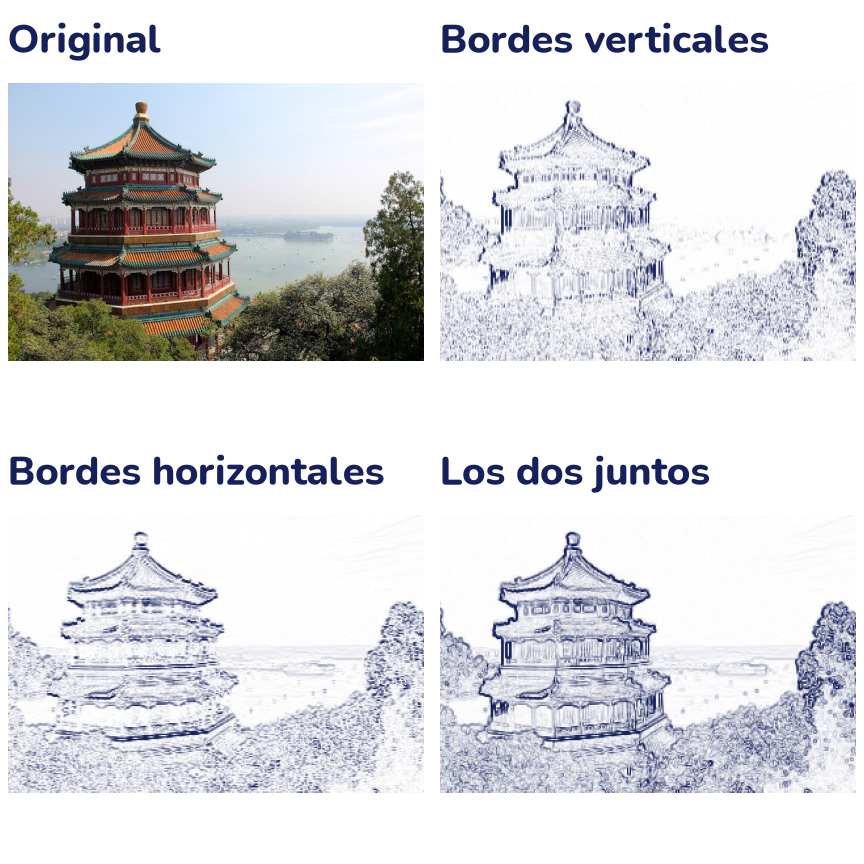

In [ ]:
from sklearn.datasets import load_sample_image

foto = load_sample_image("china.jpg")
gris = foto @ np.array([0.299, 0.587, 0.114])
# Uno de cada dos píxeles: menos ventanas que recorrer
gris = gris[::2, ::2] / 255
sobel_y = sobel_x.T

bordes_x = convolucion2d(gris, sobel_x)
bordes_y = convolucion2d(gris, sobel_y)
# Los dos bordes juntos, como la longitud de un vector
magnitud = np.sqrt(bordes_x ** 2 + bordes_y ** 2)
print("Foto en gris:", gris.shape, "  Mapa de bordes:", bordes_x.shape)
print(f"Valores de bordes_x: de {bordes_x.min():.2f} "
      f"a {bordes_x.max():.2f}")

# Blanco para el cero y tinta para los valores más altos
blanco_tinta = LinearSegmentedColormap.from_list("bt", ["white", "C0"])
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
ejes[0, 0].imshow(foto)
ejes[0, 0].set_title("Original")
# Valor absoluto: un borde es borde, suba o baje el brillo
ejes[0, 1].imshow(np.abs(bordes_x), cmap=blanco_tinta, vmax=2)
ejes[0, 1].set_title("Bordes verticales")
ejes[1, 0].imshow(np.abs(bordes_y), cmap=blanco_tinta, vmax=2)
ejes[1, 0].set_title("Bordes horizontales")
ejes[1, 1].imshow(magnitud, cmap=blanco_tinta, vmax=2)
ejes[1, 1].set_title("Los dos juntos")
for eje in ejes.flat:
    eje.axis("off")
plt.show()

El filtro de bordes verticales marca las columnas y los costados del edificio; el de bordes horizontales, las líneas de los techos. Ninguno de los dos «sabe» qué es un templo: solo responden a cambios de brillo. Pero con mapas como estos, una segunda capa puede buscar **esquinas** (donde hay borde vertical y horizontal a la vez), una tercera, **ventanas** o **tejas**, y así sucesivamente. Las CNN construyen la visión por pisos.

Fíjate en que los valores de `bordes_x` son positivos y negativos: positivo donde la imagen se aclara hacia la derecha, negativo donde se oscurece. En la figura dibujamos el valor absoluto; en la actividad, los negativos se ven en coral.

### Tamaño de la salida: *padding* y *stride*

La foto en gris mide 214 × 320 y su mapa de bordes, 212 × 318: un filtro de 3 × 3 no puede centrarse en los píxeles del borde, así que la salida pierde una fila arriba, una abajo y una columna a cada lado. Dos perillas controlan el tamaño:

- **Padding** (relleno): agregar un marco de *p* píxeles en cero alrededor de la imagen antes de filtrar. Con un filtro de 3 × 3 y *p* = 1, la salida queda del mismo tamaño que la entrada.
- **Stride** (paso): cuántos píxeles salta la ventana cada vez. Con *s* = 2 la ventana se apoya en una posición sí y una no, y la salida queda de la mitad de alto y de ancho.

Para una entrada de *n* × *n*, un filtro de *k* × *k*, relleno *p* y paso *s*, el lado de la salida es:

$$\text{salida} = \lfloor \frac{n + 2 p - k}{s} \rfloor + 1$$

Los corchetes ⌊ ⌋ significan «redondear hacia abajo», lo mismo que hace `//` en Python. Comprobémoslo con la prenda de 28 × 28:

In [ ]:
for p, s in [(0, 1), (1, 1), (1, 2), (0, 2)]:
    salida = convolucion2d(prenda, sobel_x, padding=p, stride=s)
    formula = (28 + 2 * p - 3) // s + 1
    print(f"padding {p}, stride {s}: salida {salida.shape}, "
          f"fórmula {formula}")

padding 0, stride 1: salida (26, 26), fórmula 26
padding 1, stride 1: salida (28, 28), fórmula 28
padding 1, stride 2: salida (14, 14), fórmula 14
padding 0, stride 2: salida (13, 13), fórmula 13


En el último caso, (28 − 3) / 2 = 12,5 se redondea hacia abajo a 12, y la salida mide 13: la ventana no alcanza a apoyarse en la última columna, que queda sin usar.

## Pooling: resumir y achicar

Después de una convolución suele venir un **pooling** (agrupamiento): se corta el mapa de activación en bloques de 2 × 2 y cada bloque se reemplaza por un solo número. En el **max-pooling** ese número es el máximo del bloque; en el **average-pooling**, el promedio. El mapa queda de la mitad de alto y de ancho, con la cuarta parte de los números, y las capas siguientes trabajan menos.

Para programarlo no hace falta un bucle: con `reshape` partimos el mapa en bloques y con `max` o `mean` sobre los ejes 1 y 3 resumimos cada bloque.

In [ ]:
def pooling2d(mapa, tam=2, modo="max"):
    """Resume cada bloque de tam × tam con su máximo o su promedio."""
    alto, ancho = mapa.shape[0] // tam, mapa.shape[1] // tam
    recorte = mapa[:alto * tam, :ancho * tam]
    # Ejes: (fila de bloque, fila dentro, columna de bloque, col. dentro)
    bloques = recorte.reshape(alto, tam, ancho, tam)
    if modo == "max":
        return bloques.max(axis=(1, 3))
    return bloques.mean(axis=(1, 3))

# Un punto brillante y el mismo punto movido un píxel
punto = np.zeros((4, 4))
punto[0, 0] = 1
movido = np.zeros((4, 4))
movido[1, 1] = 1
print("Iguales antes del pooling:", np.array_equal(punto, movido))
print("Iguales después del max-pooling:",
      np.array_equal(pooling2d(punto), pooling2d(movido)))
print(pooling2d(movido))

Iguales antes del pooling: False
Iguales después del max-pooling: True
[[1. 0.]
 [0. 0.]]


Esta es la razón de ser del pooling. El punto se movió, pero sigue dentro del mismo bloque de 2 × 2, así que el máximo del bloque no cambia. Después del max-pooling, un detalle que se corre un píxel da el mismo resultado: la red se vuelve un poco **invariante** a movimientos pequeños. Solo un poco: si el punto se mueve al bloque vecino, el resultado cambia. Apilar varias capas de convolución y pooling acumula esa tolerancia.

(28, 28) (26, 26) (13, 13) (13, 13)


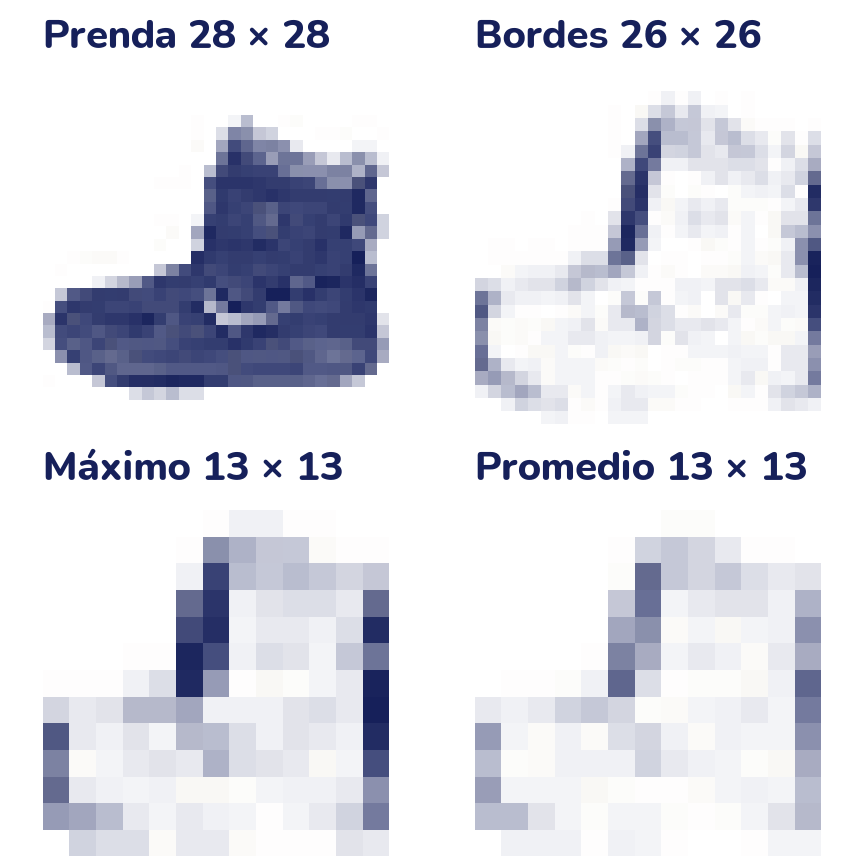

In [ ]:
bordes_prenda = np.abs(convolucion2d(prenda, sobel_x))
maximo = pooling2d(bordes_prenda, modo="max")
promedio = pooling2d(bordes_prenda, modo="promedio")
print(prenda.shape, bordes_prenda.shape, maximo.shape, promedio.shape)

# Los tres mapas de bordes con la misma escala, para poder compararlos
tope = bordes_prenda.max()
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
paneles = [(prenda, "Prenda 28 × 28", 1),
           (bordes_prenda, "Bordes 26 × 26", tope),
           (maximo, "Máximo 13 × 13", tope),
           (promedio, "Promedio 13 × 13", tope)]
for eje, (mapa, titulo, vmax) in zip(ejes.flat, paneles):
    eje.imshow(mapa, cmap=blanco_tinta, vmin=0, vmax=vmax)
    eje.set_title(titulo)
    eje.axis("off")
plt.show()

Los dos mapas de abajo tienen la cuarta parte de los números que el de bordes, y el botín todavía se reconoce. El max-pooling conserva los bordes fuertes, porque se queda con lo más alto de cada bloque; el average-pooling los suaviza, porque los mezcla con el fondo. En las capas intermedias de una CNN se usa casi siempre el máximo: lo que importa es **si** el patrón apareció en esa zona, no exactamente dónde.

## De NumPy a PyTorch

PyTorch tiene todo esto listo y mucho más rápido. `torch.nn.functional.conv2d` hace la misma cuenta que nuestra función; comprobémoslo con la prenda y el filtro Sobel. Ojo con las formas: la imagen va como (N, C, H, W) y el filtro como (filtros de salida, canales de entrada, k, k).

In [ ]:
import torch.nn.functional as F

imagen_t = torch.tensor(prenda, dtype=torch.float32).reshape(1, 1, 28, 28)
filtro_t = torch.tensor(sobel_x, dtype=torch.float32).reshape(1, 1, 3, 3)
salida_t = F.conv2d(imagen_t, filtro_t)
print(salida_t.shape)
print("¿Igual a la nuestra?",
      np.allclose(salida_t[0, 0].numpy(), convolucion2d(prenda, sobel_x),
                  atol=1e-5))

torch.Size([1, 1, 26, 26])
¿Igual a la nuestra? True


En una red no se usa la función suelta sino la capa `nn.Conv2d`, que guarda sus filtros como parámetros que se entrenan. Sus argumentos principales son `in_channels` (canales que entran), `out_channels` (cuántos filtros distintos tiene, uno por cada mapa de salida), `kernel_size`, `padding` y `stride`. Cada filtro tiene un peso por píxel de la ventana **y por canal de entrada**, más un término independiente *b*.

In [ ]:
capa = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3,
                 padding=1)
lote = torch.zeros(64, 1, 28, 28)            # (N, C, H, W)
print("Pesos de la capa:", tuple(capa.weight.shape))
print("Después de la convolución:", tuple(capa(lote).shape))
print("Después de MaxPool2d(2):  ",
      tuple(nn.MaxPool2d(2)(capa(lote)).shape))
print("Después de AvgPool2d(2):  ",
      tuple(nn.AvgPool2d(2)(capa(lote)).shape))
print("Después de AdaptiveAvgPool2d(1):",
      tuple(nn.AdaptiveAvgPool2d(1)(capa(lote)).shape))

def contar(modelo):
    """Cantidad total de números entrenables de un modelo."""
    return sum(p.numel() for p in modelo.parameters())

# Una capa densa que diera la misma salida: 16 × 28 × 28 números
densa = nn.Linear(28 * 28, 16 * 28 * 28)
print(f"Parámetros de la convolución: {contar(capa)}")
print(f"Parámetros de la capa densa:  {contar(densa)}")

Pesos de la capa: (16, 1, 3, 3)
Después de la convolución: (64, 16, 28, 28)
Después de MaxPool2d(2):   (64, 16, 14, 14)
Después de AvgPool2d(2):   (64, 16, 14, 14)
Después de AdaptiveAvgPool2d(1): (64, 16, 1, 1)
Parámetros de la convolución: 160
Parámetros de la capa densa:  9847040


Mira las formas. Con 16 filtros, cada imagen de 1 canal se convierte en **16 mapas** de 28 × 28 (gracias a `padding=1`), y el pooling los deja en 14 × 14. `AdaptiveAvgPool2d(1)` es el **pooling global**: promedia cada mapa entero y deja un solo número por canal, sea cual sea el tamaño de la imagen. Muchas CNN modernas lo usan al final, antes de la capa que clasifica.

Y mira los parámetros. La convolución tiene 16 filtros de 3 × 3 = 144 pesos, más 16 términos independientes *b*: 160 números. Una capa densa que convirtiera la imagen en esos mismos 12 544 números de salida necesitaría casi diez millones. La diferencia es que la convolución **comparte** sus pesos: el mismo filtro de 9 números se usa en todas las posiciones de la imagen. Eso tiene dos ventajas: la red es mucho más chica, y lo que aprende en un rincón de la imagen (un borde, una costura) lo reconoce en cualquier otro.

### El campo receptivo

Cada casilla de la primera convolución depende de una ventana de 3 × 3 píxeles de la imagen: ese es su **campo receptivo**. Después de un max-pooling de 2 × 2, cada casilla resume cuatro ventanas de 3 × 3 que se solapan (un bloque de 2 × 2) y en total ve 4 × 4 píxeles. Una segunda convolución de 3 × 3 sobre ese mapa achicado mezcla tres casillas en cada dirección, que en la imagen original abarcan 8 × 8 píxeles. Cada piso de la red ve un pedazo más grande de la imagen: por eso las primeras capas encuentran bordes y las últimas, partes enteras de una prenda.

## Una CNN para FashionMNIST

La arquitectura típica repite un bloque **convolución → ReLU → pooling**: la convolución busca patrones, la ReLU deja pasar solo los positivos (el patrón está o no está) y el pooling achica. Al final se aplanan los mapas y una capa `nn.Linear` decide la clase.

### Los datos

Para que todo el tema corra en menos de un par de minutos en una computadora sin GPU, entrenamos con **10 000 imágenes** elegidas al azar de las 60 000 de entrenamiento, y validamos con **otras 2000** de esas 60 000, distintas de las primeras, que el modelo nunca ve mientras aprende. Con la validación comparamos redes y decisiones. Las 10 000 imágenes de prueba no se tocan en todo el tema: quedan para una sola medición final, en el mini-proyecto (tema 7). Además, cargamos todas las imágenes de una vez como un solo tensor y usamos `TensorDataset`, que entrega pares (imagen, etiqueta) de ese tensor: así no hay que convertir cada imagen en cada época.

También **normalizamos** las imágenes: les restamos la media de los píxeles y las dividimos por su desviación estándar, calculadas con el entrenamiento, como hacías con las columnas de una tabla en los temas anteriores. Así los valores quedan centrados en cero, y el entrenamiento es más estable.

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

g = torch.Generator().manual_seed(0)
orden = torch.randperm(len(entrenamiento), generator=g)
idx_ent = orden[:10000]           # para entrenar
idx_val = orden[10000:12000]      # para validar: otras 2000, sin repetir

x_ent = entrenamiento.data[idx_ent].float() / 255
x_val = entrenamiento.data[idx_val].float() / 255
y_ent = entrenamiento.targets[idx_ent]
y_val = entrenamiento.targets[idx_val]

# Media y desviación del entrenamiento, para las dos partes
media, desv = x_ent.mean().item(), x_ent.std().item()
print(f"Media de los píxeles: {media:.3f}   desviación: {desv:.3f}")
# unsqueeze(1) agrega el eje del canal: (N, 28, 28) -> (N, 1, 28, 28)
x_ent = ((x_ent - media) / desv).unsqueeze(1)
x_val = ((x_val - media) / desv).unsqueeze(1)
print("Entrenamiento:", tuple(x_ent.shape), " Validación:",
      tuple(x_val.shape))

cargador_ent = DataLoader(TensorDataset(x_ent, y_ent), batch_size=64,
                          shuffle=True,
                          generator=torch.Generator().manual_seed(0))
cargador_val = DataLoader(TensorDataset(x_val, y_val), batch_size=500)

Media de los píxeles: 0.287   desviación: 0.354
Entrenamiento: (10000, 1, 28, 28)  Validación: (2000, 1, 28, 28)


### El bucle de entrenamiento

Para entrenar usamos la función `entrenar` del tema 18, sin cambiar nada. Si no la tienes a mano, cópiala en tu cuaderno tal como está aquí; en el tema 18 se explica línea por línea.

In [ ]:
import torch
from torch import nn


def evaluar(modelo, cargador, funcion_perdida, dispositivo="cpu"):
    """Pérdida media y exactitud de `modelo` sobre `cargador`."""
    modelo.eval()
    suma, aciertos, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            salida = modelo(x)
            suma += funcion_perdida(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
    return suma / total, aciertos / total


def entrenar(modelo, cargador_ent, cargador_val, epocas, optimizador,
             funcion_perdida=None, planificador=None, dispositivo="cpu",
             mostrar=True):
    """Entrena `modelo` y devuelve el historial de cada época."""
    if funcion_perdida is None:
        funcion_perdida = nn.CrossEntropyLoss()
    modelo.to(dispositivo)
    historial = {"perdida_ent": [], "exactitud_ent": [],
                 "perdida_val": [], "exactitud_val": []}
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma, aciertos, total = 0.0, 0, 0
        for x, y in cargador_ent:
            x, y = x.to(dispositivo), y.to(dispositivo)
            optimizador.zero_grad()
            salida = modelo(x)
            perdida = funcion_perdida(salida, y)
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
        if planificador is not None:
            planificador.step()
        perdida_val, exactitud_val = evaluar(
            modelo, cargador_val, funcion_perdida, dispositivo)
        historial["perdida_ent"].append(suma / total)
        historial["exactitud_ent"].append(aciertos / total)
        historial["perdida_val"].append(perdida_val)
        historial["exactitud_val"].append(exactitud_val)
        if mostrar:
            print(f"Época {epoca}: pérdida {suma / total:.3f}, "
                  f"validación {perdida_val:.3f}, "
                  f"exactitud de validación {exactitud_val:.3f}")
    return historial

### CNN contra MLP, con el mismo tamaño

Para que la comparación sea justa, armamos dos redes con casi la misma cantidad de parámetros, unos 20 000:

- La **CNN** tiene dos bloques convolución → ReLU → max-pooling, con 16 y 32 filtros. La imagen pasa de (1, 28, 28) a (16, 14, 14) y después a (32, 7, 7); esos 32 × 7 × 7 = 1568 números se aplanan y una capa lineal los convierte en 10 puntajes, uno por clase.
- El **MLP** aplana la imagen en 784 números, tiene una capa oculta de 26 neuronas y una de salida de 10. Con 26 neuronas queda casi del mismo tamaño que la CNN.

In [ ]:
torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),   # (16, 28, 28)
    nn.ReLU(),
    nn.MaxPool2d(2),                              # (16, 14, 14)
    nn.Conv2d(16, 32, kernel_size=3, padding=1),  # (32, 14, 14)
    nn.ReLU(),
    nn.MaxPool2d(2),                              # (32, 7, 7)
    nn.Flatten(),                                 # 1568
    nn.Linear(32 * 7 * 7, 10),
)
torch.manual_seed(0)
mlp = nn.Sequential(
    nn.Flatten(),                                 # 784
    nn.Linear(28 * 28, 26),
    nn.ReLU(),
    nn.Linear(26, 10),
)
print(f"Parámetros de la CNN: {contar(cnn)}")
print(f"Parámetros del MLP:   {contar(mlp)}")

Parámetros de la CNN: 20490
Parámetros del MLP:   20680


Entrenamos las dos con lo mismo: Adam con tasa 0,001, lotes de 64 y 8 épocas. Primero la CNN:

In [ ]:
torch.manual_seed(0)
hist_cnn = entrenar(cnn, cargador_ent, cargador_val, epocas=8,
                    optimizador=torch.optim.Adam(cnn.parameters(),
                                                 lr=1e-3),
                    dispositivo=device)

Época 1: pérdida 0.800, validación 0.559, exactitud de validación 0.794
Época 2: pérdida 0.471, validación 0.442, exactitud de validación 0.847
Época 3: pérdida 0.415, validación 0.454, exactitud de validación 0.836
Época 4: pérdida 0.368, validación 0.414, exactitud de validación 0.851
Época 5: pérdida 0.346, validación 0.394, exactitud de validación 0.855
Época 6: pérdida 0.319, validación 0.374, exactitud de validación 0.865
Época 7: pérdida 0.302, validación 0.403, exactitud de validación 0.858
Época 8: pérdida 0.285, validación 0.362, exactitud de validación 0.873


Y ahora el MLP:

Época 1: pérdida 0.790, validación 0.583, exactitud de validación 0.793
Época 2: pérdida 0.522, validación 0.498, exactitud de validación 0.830
Época 3: pérdida 0.470, validación 0.498, exactitud de validación 0.824
Época 4: pérdida 0.435, validación 0.475, exactitud de validación 0.831
Época 5: pérdida 0.413, validación 0.471, exactitud de validación 0.834
Época 6: pérdida 0.390, validación 0.454, exactitud de validación 0.834
Época 7: pérdida 0.376, validación 0.440, exactitud de validación 0.854
Época 8: pérdida 0.362, validación 0.427, exactitud de validación 0.846


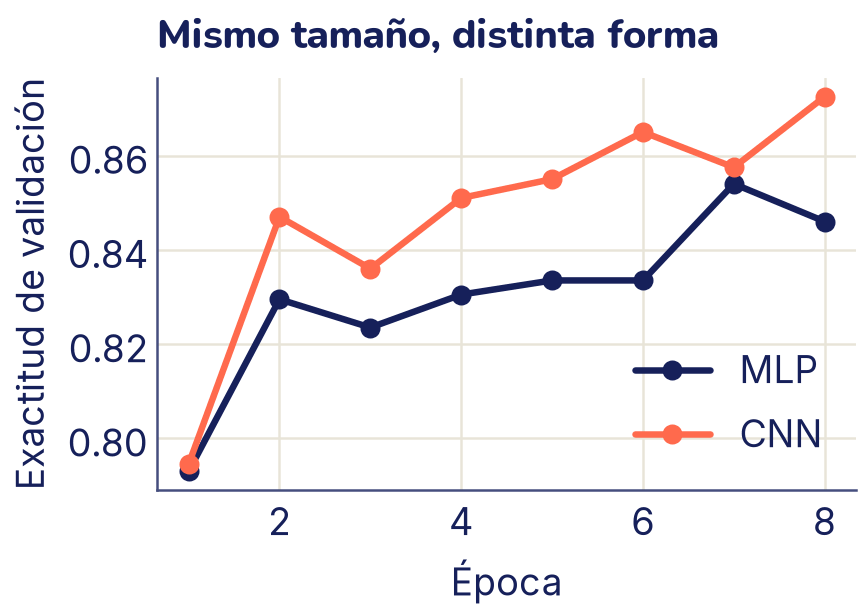

In [ ]:
torch.manual_seed(0)
hist_mlp = entrenar(mlp, cargador_ent, cargador_val, epocas=8,
                    optimizador=torch.optim.Adam(mlp.parameters(),
                                                 lr=1e-3),
                    dispositivo=device)

epocas = range(1, 9)
plt.plot(epocas, hist_mlp["exactitud_val"], "o-", color="C0",
         label="MLP")
plt.plot(epocas, hist_cnn["exactitud_val"], "o-", color="C1",
         label="CNN")
plt.xlabel("Época")
plt.ylabel("Exactitud de validación")
plt.title("Mismo tamaño, distinta forma")
plt.legend()
plt.show()

Las dos redes tienen casi el mismo tamaño (20 490 y 20 680 parámetros), vieron las mismas imágenes el mismo número de veces y se entrenaron con el mismo optimizador. Aun así, después de 8 épocas la CNN acierta el **87,3 %** de las prendas de validación y el MLP, el **84,6 %**. Dicho al revés: el MLP se equivoca en el 15,4 % de las prendas y la CNN en el 12,7 %, cerca de una sexta parte menos de errores. La pérdida de validación cuenta lo mismo: 0,362 contra 0,427.

La diferencia no viene de tener más parámetros, sino de **cómo** se usan. El MLP gasta casi todos sus pesos en conectar cada píxel con cada neurona oculta, y tiene que aprender por separado que una costura en la esquina y una costura en el centro son lo mismo. La CNN gasta sus pesos en filtros que se reutilizan en toda la imagen.

Dos advertencias honestas. Primero, la CNN es más lenta de entrenar con los mismos parámetros, porque cada filtro se aplica en cientos de posiciones; en una computadora sin GPU lo notas. Segundo, son números de **una** corrida con 10 000 imágenes y 8 épocas: con otra semilla, otros datos o más épocas cambian un poco. Fíjate que las curvas suben y bajan de una época a otra (la de la CNN baja en las épocas 3 y 7): con 2000 imágenes de validación, una diferencia de un punto porcentual son apenas 20 prendas. Por eso no basta mirar una época: la CNN queda por encima en todas, aunque en la primera y en la séptima por menos de medio punto.

### ¿Qué aprendió la CNN?

Los filtros de la primera capa son 16 tablas de 3 × 3 que empezaron al azar. Podemos dibujarlos: en cada uno, la tinta marca los pesos más altos y el blanco, los más bajos.

(16, 1, 3, 3)


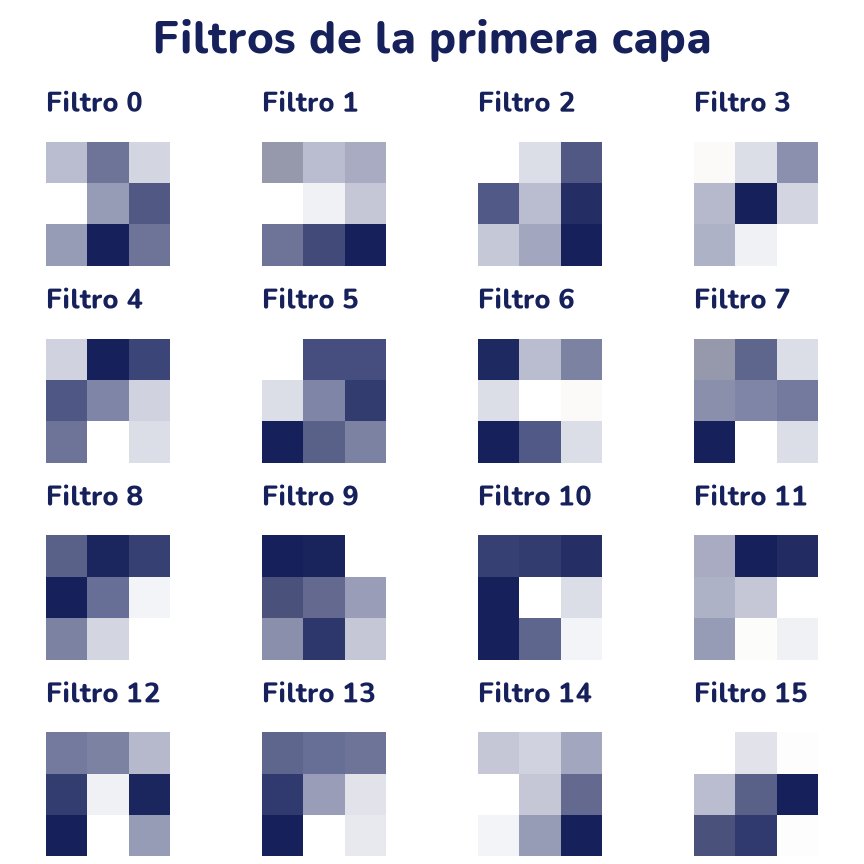

In [ ]:
# cpu(): por si la red se entrenó en una GPU
filtros = cnn[0].weight.detach().cpu()        # (16, 1, 3, 3)
print(tuple(filtros.shape))

fig, ejes = plt.subplots(4, 4, figsize=(4.8, 4.8))
for k, eje in enumerate(ejes.flat):
    eje.imshow(filtros[k, 0], cmap=blanco_tinta)
    eje.set_title(f"Filtro {k}", fontsize=11)
    eje.axis("off")
plt.suptitle("Filtros de la primera capa")
plt.show()

No se parecen al Sobel ordenado que escribimos a mano: después de solo 8 épocas siguen teniendo bastante del azar con que empezaron. Pero varios tienen un lado oscuro y otro claro, como el filtro 10 (tinta arriba y a la izquierda) o el 2 (tinta abajo a la derecha): responden a cambios de brillo en una dirección, es decir, son **detectores de bordes**. Nadie le dijo a la red que buscara bordes; los encontró porque le sirven para separar las clases.

Más interesante todavía es ver qué hace cada filtro con una prenda. Pasamos una imagen de validación por la primera convolución y su ReLU y dibujamos los 16 mapas de activación.

Etiqueta: botín
(16, 28, 28)


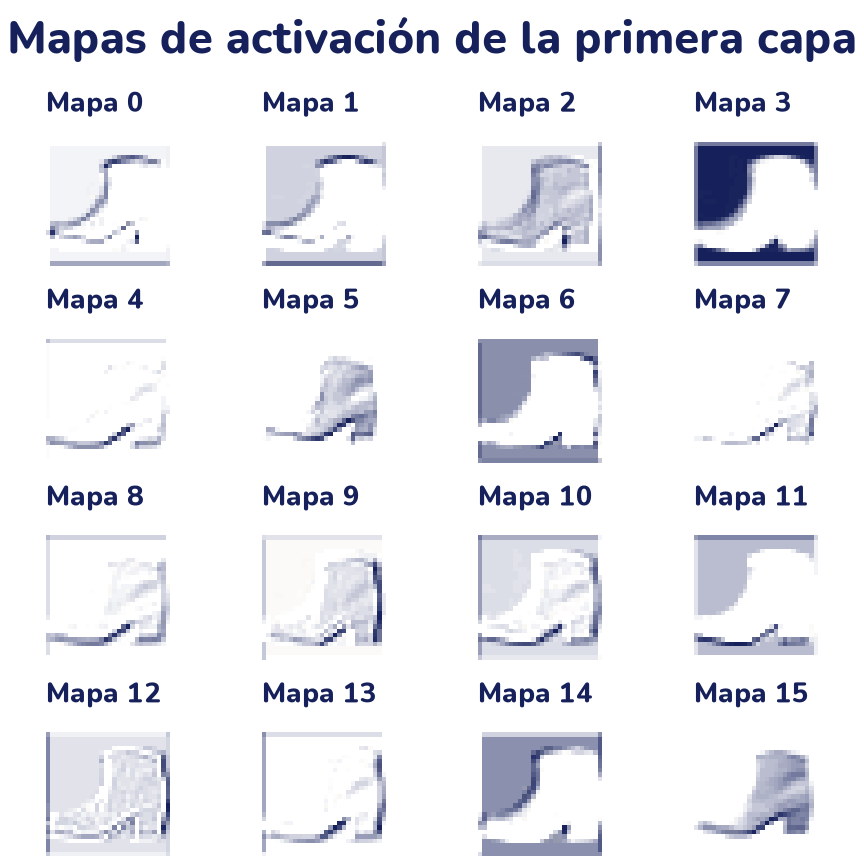

In [ ]:
# Una prenda de validación: la que está en la posición 1
imagen = x_val[1:2].to(device)                # (1, 1, 28, 28)
print("Etiqueta:", nombres[y_val[1]])
with torch.no_grad():
    mapas = cnn[1](cnn[0](imagen))[0].cpu()   # (16, 28, 28)
print(tuple(mapas.shape))

fig, ejes = plt.subplots(4, 4, figsize=(4.8, 4.8))
for k, eje in enumerate(ejes.flat):
    eje.imshow(mapas[k], cmap=blanco_tinta)
    eje.set_title(f"Mapa {k}", fontsize=11)
    eje.axis("off")
plt.suptitle("Mapas de activación de la primera capa")
plt.show()

Cada mapa es el mismo botín visto con un filtro distinto. Algunos marcan sobre todo los bordes de abajo, la suela y el taco (como el 4, el 7 y el 13); otros, el contorno de arriba de la caña (el 0 y el 1), y otros se encienden sobre casi toda la prenda (el 2, el 5 y el 15). Los mapas 3, 6, 11 y 14 hacen algo que no esperábamos: se encienden en el **fondo** y quedan apagados sobre la prenda. También eso es información útil: la silueta de lo que no es prenda dice mucho de la forma de la prenda.

La segunda capa de la CNN recibe estos 16 mapas (achicados por el pooling) como si fueran 16 canales de una imagen, y combina sus filtros sobre todos a la vez: así arma patrones más grandes, como un cuello o una manga.

## Aumentación: más datos sin salir a fotografiar

Una CNN grande con pocas imágenes termina memorizándolas: sobreajusta, como viste en el tema 19. Conseguir más fotos cuesta, pero hay un truco barato. Si una polera volteada como en un espejo sigue siendo una polera, podemos **inventar** imágenes nuevas a partir de las que tenemos: voltearlas, recortarlas un poco corridas, ponerles ruido. Eso se llama **aumentación de datos**, y es una forma de regularización: la red ve en cada época una versión un poco distinta de cada imagen, y le cuesta más memorizar.

`torchvision.transforms` trae las transformaciones listas, y `transforms.Compose` las encadena:

- `RandomHorizontalFlip(p=0.5)` voltea la imagen de izquierda a derecha la mitad de las veces.
- `RandomCrop(28, padding=3)` agrega un marco de 3 píxeles y recorta un cuadro de 28 × 28 en una posición al azar: la prenda queda corrida hasta 3 píxeles en cualquier dirección.
- Para el **ruido gaussiano** (con la distribución normal del tema 5) escribimos una función corta y la envolvemos en `transforms.Lambda`.

Forma de cada versión: (1, 28, 28)


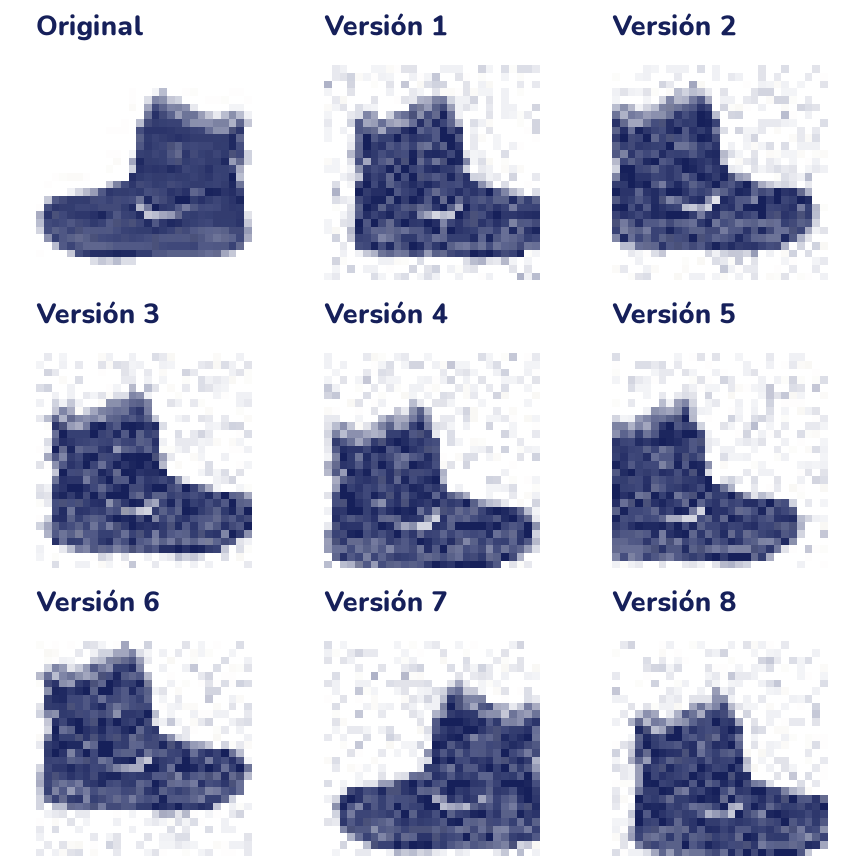

In [ ]:
from torchvision import transforms

def ruido(x):
    """Suma a cada píxel un número al azar de desviación 0,1."""
    return x + 0.1 * torch.randn_like(x)

aumentar = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(28, padding=3),
    transforms.Lambda(ruido),
])

torch.manual_seed(0)
# Una imagen de entrenamiento, sin normalizar: (1, 28, 28)
original = entrenamiento.data[0].float().unsqueeze(0) / 255
fig, ejes = plt.subplots(3, 3, figsize=(4.8, 4.8))
for k, eje in enumerate(ejes.flat):
    version = original if k == 0 else aumentar(original)
    eje.imshow(version[0], cmap=blanco_tinta, vmin=0, vmax=1)
    eje.set_title("Original" if k == 0 else f"Versión {k}", fontsize=11)
    eje.axis("off")
plt.show()
print("Forma de cada versión:", tuple(aumentar(original).shape))

Las ocho versiones son el mismo botín: unas miran hacia el otro lado, todas están un poco corridas y tienen un granulado de ruido. Para la red, son ocho ejemplos distintos con la misma etiqueta.

Para elegir aumentaciones hay que hacerse dos preguntas, y una regla más:

- **¿Cambia la respuesta?** Si cambia, la aumentación enseña algo falso. Una prenda volteada de izquierda a derecha sigue siendo la misma prenda; un 2 en espejo, en cambio, ya no es un 2, así que con dígitos ese volteo no sirve.
- **¿Se parece a lo que la red verá después?** Que la etiqueta no cambie no basta: la aumentación ayuda cuando imita variaciones que sí aparecen en las fotos nuevas. En FashionMNIST todas las prendas están derechas, así que voltearlas de arriba abajo no tiene sentido. Con el volteo horizontal hay que tener cuidado: en el ejercicio 4 del tema 18 viste que todos los zapatos del conjunto miran hacia el mismo lado. Voltearlos no cambia la etiqueta, pero muestra a la red zapatos que en la prueba no van a aparecer. Puede ayudar con las demás prendas o puede gastar esfuerzo de la red en un caso que no llega: la única forma de saberlo es medirlo con la validación.
- **Solo en el entrenamiento.** La validación y la prueba se miden con las imágenes tal cual, para comparar siempre contra lo mismo.

Con fotos en color se usan además cambios de brillo y contraste (`ColorJitter`) y recortes de distinto tamaño (`RandomResizedCrop`). Un conjunto clásico para practicar con fotos en color es **CIFAR-10**: 60 000 fotos de 32 × 32 de aviones, autos, pájaros, gatos y otras seis clases. Se baja con `datasets.CIFAR10(root="datos", download=True)`, pero pesa unos 170 MB y, sin GPU, entrenar con él es lento: úsalo como opción si tu conexión y tu paciencia lo permiten. Todo el código de este tema sirve igual, cambiando `in_channels=1` por `in_channels=3` y el tamaño de la capa final.

En el mini-proyecto vas a aplicar la aumentación en el entrenamiento y a medir si ayuda.

## Lo que aprendiste y lo que sigue

- Una **convolución** desliza un filtro chico por la imagen y en cada posición calcula un producto punto: el **mapa de activación** dice dónde aparece el patrón del filtro. El filtro **Sobel** encuentra bordes.
- El lado de la salida es ⌊(*n* + 2*p* − *k*) / *s*⌋ + 1. El **padding** conserva el tamaño; el **stride** lo achica.
- El **pooling** resume bloques de 2 × 2 con su máximo o su promedio: achica los mapas y da algo de tolerancia a movimientos pequeños.
- Una convolución **comparte** sus pesos en toda la imagen: tiene muchísimos menos parámetros que una capa densa y reconoce un patrón en cualquier lugar.
- Con el mismo número de parámetros, una **CNN** clasifica las prendas mejor que un **MLP**, porque aprovecha que los píxeles vecinos están relacionados.
- La **aumentación** crea versiones nuevas de cada imagen de entrenamiento y ayuda a no sobreajustar, siempre que no cambie la respuesta correcta.

Los filtros de una CNN aprenden a ver bordes, texturas y formas sin que nadie se los escriba. En el tema 26 vas a usar CNN enormes ya entrenadas con millones de fotos y a adaptarlas a tus propios problemas, y en el 27, a encontrar **dónde** está cada objeto dentro de una foto.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `convolucion2d`, `pooling2d`, `contar`, `sobel_x`, `prenda`, `entrenamiento`, `idx_ent`, `media`, `desv`, `aumentar`, `cargador_val` y la función `entrenar`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio con lápiz y papel antes de abrir la respuesta: en este tema, hacer las cuentas a mano es lo que fija la idea.

## Ejercicios

### 1. Una convolución a mano

Esta imagen *I* de 4 × 4 y este filtro *K* de 3 × 3:

$$I = [ \begin{array}{l} 1 & 2 & 0 & 1 \\[0.6em] 0 & 1 & 3 & 1 \\[0.6em] 2 & 1 & 0 & 0 \\[0.6em] 1 & 0 & 2 & 1 \end{array} ] \qquad K = [ \begin{array}{l} 1 & 0 & - 1 \\[0.6em] 1 & 0 & - 1 \\[0.6em] 1 & 0 & - 1 \end{array} ]$$

a) Sin padding y con stride 1, ¿de qué tamaño es la salida? Calcula cada casilla a mano.

b) ¿Qué tamaño tendría la salida con padding 1 y stride 1? ¿Y sin padding y con stride 2?

c) Comprueba todo con `convolucion2d`.

<details>
<summary>Respuesta</summary>

a) Con *n* = 4 y *k* = 3, la salida mide (4 − 3) / 1 + 1 = 2, es decir, 2 × 2. El filtro suma la columna izquierda de la ventana y le resta la derecha:

- Arriba a la izquierda (filas 0 a 2, columnas 0 a 2): (1 + 0 + 2) − (0 + 3 + 0) = **0**.
- Arriba a la derecha (columnas 1 a 3): (2 + 1 + 1) − (1 + 1 + 0) = **2**.
- Abajo a la izquierda (filas 1 a 3, columnas 0 a 2): (0 + 2 + 1) − (3 + 0 + 2) = **−2**.
- Abajo a la derecha (columnas 1 a 3): (1 + 1 + 0) − (1 + 0 + 1) = **0**.

b) Con padding 1: (4 + 2 − 3) / 1 + 1 = 4, la salida es de 4 × 4, como la entrada. Sin padding y con stride 2: ⌊(4 − 3) / 2⌋ + 1 = 0 + 1 = 1, una sola casilla (la de arriba a la izquierda).

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
imagen_4 = np.array([[1, 2, 0, 1],
                     [0, 1, 3, 1],
                     [2, 1, 0, 0],
                     [1, 0, 2, 1]])
filtro_3 = np.array([[1, 0, -1],
                     [1, 0, -1],
                     [1, 0, -1]])
print(convolucion2d(imagen_4, filtro_3))
print(convolucion2d(imagen_4, filtro_3, padding=1).shape)
print(convolucion2d(imagen_4, filtro_3, stride=2))

### 2. Tamaños de salida en cinco capas

Una red recibe fotos en color de 32 × 32, es decir, tensores de forma (N, 3, 32, 32). Predice la forma de la salida de cada capa, una tras otra:

1. `nn.Conv2d(3, 8, kernel_size=5)`
2. `nn.MaxPool2d(2)`
3. `nn.Conv2d(8, 16, kernel_size=3, padding=1)`
4. `nn.Conv2d(16, 16, kernel_size=3, stride=2)`
5. `nn.MaxPool2d(2)`

¿Cuántos números le llegan a la capa lineal si después se aplana? Comprueba con PyTorch pasando un tensor de ceros capa por capa.

<details>
<summary>Respuesta</summary>

1. (32 − 5) / 1 + 1 = 28, con 8 filtros: **(N, 8, 28, 28)**.
2. El pooling de 2 × 2 divide el lado por dos: **(N, 8, 14, 14)**.
3. Con un filtro de 3 y padding 1 el tamaño se conserva: **(N, 16, 14, 14)**.
4. ⌊(14 − 3) / 2⌋ + 1 = ⌊5,5⌋ + 1 = 6: **(N, 16, 6, 6)**.
5. **(N, 16, 3, 3)**.

Al aplanar quedan 16 × 3 × 3 = **144** números por imagen. Fíjate en que el número de canales lo decide solo `out_channels`, y el alto y el ancho, solo el filtro, el padding, el stride y el pooling.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
capas = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=5),
    nn.MaxPool2d(2),
    nn.Conv2d(8, 16, kernel_size=3, padding=1),
    nn.Conv2d(16, 16, kernel_size=3, stride=2),
    nn.MaxPool2d(2),
)
x = torch.zeros(1, 3, 32, 32)
for capa in capas:
    x = capa(x)
    print(f"{type(capa).__name__:10} -> {tuple(x.shape)}")
print("Números al aplanar:", x.flatten(1).shape[1])

### 3. Pooling a mano

Para este mapa de activación *A* de 4 × 4, calcula a mano el max-pooling y el average-pooling de 2 × 2. Después compruébalo con `pooling2d`.

$$A = [ \begin{array}{l} 1 & 3 & 2 & 0 \\[0.6em] 4 & 2 & 1 & 1 \\[0.6em] 0 & 1 & 5 & 2 \\[0.6em] 2 & 2 & 1 & 0 \end{array} ]$$

<details>
<summary>Respuesta</summary>

Los cuatro bloques de 2 × 2 son {1, 3, 4, 2}, {2, 0, 1, 1}, {0, 1, 2, 2} y {5, 2, 1, 0}.

- Max-pooling: 4, 2, 2 y 5.
- Average-pooling: 10 / 4 = 2,5; 4 / 4 = 1; 5 / 4 = 1,25; 8 / 4 = 2.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
mapa_4 = np.array([[1, 3, 2, 0],
                   [4, 2, 1, 1],
                   [0, 1, 5, 2],
                   [2, 2, 1, 0]])
print(pooling2d(mapa_4, modo="max"))
print(pooling2d(mapa_4, modo="promedio"))

### 4. Contar parámetros: CNN contra MLP

a) Una capa `nn.Conv2d(C_ent, C_sal, kernel_size=k)` tiene un filtro por canal de salida, y cada filtro tiene *k* × *k* pesos **por cada canal de entrada**, más un término independiente *b*. Escribe la fórmula de su número de parámetros.

b) Usa la fórmula para contar los parámetros de las tres convoluciones del ejercicio 2, más una capa `nn.Linear(144, 10)` al final.

c) Compáralo con un MLP que recibe la misma foto aplanada (3 × 32 × 32 = 3072 números), con una capa oculta de 64 neuronas y una salida de 10.

d) Comprueba los dos totales con `contar`.

<details>
<summary>Respuesta</summary>

a) (*k* · *k* · C_ent + 1) · C_sal.

b) Las tres convoluciones y la capa lineal:

- `Conv2d(3, 8, 5)`: (5 · 5 · 3 + 1) · 8 = 76 · 8 = 608.
- `Conv2d(8, 16, 3)`: (3 · 3 · 8 + 1) · 16 = 73 · 16 = 1168.
- `Conv2d(16, 16, 3)`: (3 · 3 · 16 + 1) · 16 = 145 · 16 = 2320.
- `Linear(144, 10)`: 144 · 10 + 10 = 1450.

En total, **5546** parámetros. Los pooling no tienen parámetros: solo eligen o promedian.

c) El MLP: 3072 · 64 + 64 = 196 672 en la capa oculta y 64 · 10 + 10 = 650 en la salida, en total **197 322**, unas 36 veces más que la CNN. Y eso que tiene una sola capa oculta, bastante angosta.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
cnn_32 = nn.Sequential(*capas, nn.Flatten(), nn.Linear(144, 10))
mlp_32 = nn.Sequential(nn.Flatten(), nn.Linear(3 * 32 * 32, 64),
                       nn.ReLU(), nn.Linear(64, 10))
print("CNN:", contar(cnn_32), "  MLP:", contar(mlp_32))

### 5. Encuentra el error

Este modelo quería ser la CNN de la teoría, pero al pasarle un lote falla. Lee el mensaje de error, explica qué pasó y corrígelo de dos formas distintas.

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
modelo_roto = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 10),
)
lote = torch.zeros(64, 1, 28, 28)
print(modelo_roto(lote).shape)

Traceback (most recent call last):
  ...
RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x6272 and 1568x10)


<details>
<summary>Respuesta</summary>

Falta el segundo `nn.MaxPool2d(2)`. Con un solo pooling, los mapas quedan de 14 × 14 y no de 7 × 7, así que `Flatten` entrega 32 × 14 × 14 = 6272 números por imagen. La capa lineal espera 1568 (= 32 × 7 × 7) y no puede multiplicar: el mensaje dice exactamente eso, una matriz de 64 × 6272 (el lote) contra una de 1568 × 10 (los pesos).

Las dos correcciones: agregar el `nn.MaxPool2d(2)` que falta después de la segunda ReLU, o dejar el modelo como está y cambiar la capa final a `nn.Linear(32 * 14 * 14, 10)`. La segunda funciona, pero la capa lineal queda con cuatro veces más pesos.

Para encontrar estos errores, pasa un lote de ceros capa por capa e imprime las formas, como en el ejercicio 2:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
x = torch.zeros(64, 1, 28, 28)
for capa in modelo_roto[:-1]:
    x = capa(x)
print("Llegan a la capa lineal:", tuple(x.shape))

### 6. Tres filtros de la actividad

a) ¿Qué filtro de 3 × 3 deja la imagen exactamente igual (salvo el borde que se pierde)? Compruébalo con `prenda`.

b) El filtro de **desenfoque** tiene los nueve pesos iguales a 1/9. ¿Qué calcula en cada casilla?

c) El filtro de **nitidez** de la actividad tiene un 5 en el centro, −1 arriba, abajo, a la izquierda y a la derecha, y 0 en las esquinas. ¿Cuánto da sobre una zona pareja, donde todos los píxeles valen lo mismo? ¿Y por qué hace más marcados los bordes?

<details>
<summary>Respuesta</summary>

a) El filtro con un 1 en el centro y 0 en todo lo demás: cada casilla de la salida es el píxel del centro de la ventana. Como sin padding se pierde un píxel en cada borde, la salida es igual a la imagen sin su marco.

b) El **promedio** de los nueve píxeles de la ventana. Cada píxel se mezcla con sus vecinos y los bordes se difuminan.

c) Sobre una zona pareja de valor *v* da 5*v* − 4*v* = *v*: la deja igual, porque los pesos suman 1. Cerca de un borde, en cambio, el píxel del centro pesa 5 y se le restan sus vecinos: si el centro es más claro que ellos, queda todavía más claro, y si es más oscuro, más oscuro. La diferencia entre los dos lados del borde crece.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
identidad = np.array([[0, 0, 0],
                      [0, 1, 0],
                      [0, 0, 0]])
copia = convolucion2d(prenda, identidad)
print(copia.shape, np.allclose(copia, prenda[1:-1, 1:-1]))

nitidez = np.array([[0, -1, 0],
                    [-1, 5, -1],
                    [0, -1, 0]])
pareja = np.full((5, 5), 0.6)
print(convolucion2d(pareja, nitidez).round(2))

### 7. ¿Qué aumentaciones tienen sentido?

Para cada problema, di si usarías el volteo horizontal, el volteo vertical y una rotación pequeña (de unos 10°), y por qué:

1. Reconocer dígitos escritos a mano.
2. Reconocer señales de tránsito.
3. Clasificar cultivos en fotos tomadas desde un satélite, mirando hacia abajo.
4. Reconocer prendas de FashionMNIST.

<details>
<summary>Respuesta</summary>

1. **Dígitos:** volteos no, porque cambian la respuesta (un 2 en espejo no es un 2; un 6 de cabeza parece un 9). Una rotación pequeña sí: la gente escribe un poco inclinado.
2. **Señales de tránsito:** volteos no. Una flecha de «gire a la izquierda» volteada es «gire a la derecha», y el texto de un letrero queda al revés. Una rotación pequeña sí, porque las fotos se toman desde ángulos distintos.
3. **Cultivos desde un satélite:** los dos volteos y cualquier rotación, incluso de 90°. Desde arriba no hay «arriba» ni «abajo»: un campo de soya es soya en cualquier orientación.
4. **Prendas:** volteo vertical no: no cambia la etiqueta, pero las fotos del conjunto siempre muestran las prendas derechas y la red nunca va a ver un botín de cabeza. El volteo horizontal tampoco cambia la etiqueta (una camisa en espejo sigue siendo una camisa), pero en el ejercicio 4 del tema 18 viste que todos los zapatos de FashionMNIST miran hacia el mismo lado: para el calzado, el volteo crea fotos que en la prueba no aparecen. Si ayuda o no, no se decide con un argumento: se mide en la validación, con y sin volteo. Una rotación pequeña es razonable, porque una prenda puede quedar un poco torcida en la foto.

Las preguntas de fondo son siempre dos: **¿la etiqueta sigue siendo correcta después de transformar la imagen?** Si la respuesta es no, esa aumentación enseña algo falso. Y **¿la imagen transformada se parece a las que llegarán después?** Si no se parece, la aumentación puede no ayudar, y hay que medirlo.

</details>

## Mini-proyecto: una CNN con aumentación

Vas a entrenar una CNN para FashionMNIST con aumentación de datos y a superar a las dos redes de la teoría, la CNN y el MLP de unos 20 000 parámetros.

**Los datos.** Los mismos de la teoría. Si tu computadora o Colab lo aguantan, usa más de 10 000 imágenes de entrenamiento: con las 58 000 que no son de validación (`orden[:10000]` junto con `orden[12000:]`), cada época tarda unas seis veces más. Las decisiones se toman con las 2000 de validación. Las 10 000 imágenes de prueba quedan para el paso 6, y no se usan antes.

**Cómo aplicar la aumentación en el entrenamiento.** `TensorDataset` entrega las imágenes tal cual. Para que cada época vea versiones distintas, escribe un `Dataset` propio que aplique `aumentar` cada vez que se le pide una imagen. Este es un punto de partida que ya funciona: aumenta primero, sobre la imagen entre 0 y 1, y normaliza después, con la misma media y desviación de la teoría.

In [ ]:
from torch.utils.data import Dataset

class ConAumentacion(Dataset):
    """Imágenes de 0 a 1 que se aumentan y normalizan al pedirlas."""

    def __init__(self, imagenes, etiquetas, transformacion=None):
        self.imagenes = imagenes            # (N, 1, 28, 28)
        self.etiquetas = etiquetas
        self.transformacion = transformacion

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, i):
        x = self.imagenes[i]
        if self.transformacion is not None:
            x = self.transformacion(x)
        return (x - media) / desv, self.etiquetas[i]

imagenes_ent = entrenamiento.data[idx_ent].float().unsqueeze(1) / 255
datos_aumentados = ConAumentacion(imagenes_ent,
                                  entrenamiento.targets[idx_ent],
                                  transformacion=aumentar)
cargador_aum = DataLoader(datos_aumentados, batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(0))
x, y = next(iter(cargador_aum))
print(tuple(x.shape), tuple(y.shape))

(64, 1, 28, 28) (64,)


**Pasos.**

1. **La línea de base.** Anota la exactitud de validación de la CNN y del MLP de la teoría después de 8 épocas (`hist_cnn` y `hist_mlp`). Esos son los números a superar, porque se midieron en las mismas condiciones que vas a usar: los mismos datos, la misma validación y las mismas épocas. Los MLP de los temas 18 y 19 no sirven de referencia: se entrenaron con otras imágenes y otras épocas, y se midieron con otro conjunto. Si cambias los datos o las épocas, vuelve a entrenar también la línea de base con esos cambios.
2. **Tu CNN.** Prueba una CNN un poco más grande que la de la teoría: por ejemplo, 32 y 64 filtros, o un tercer bloque convolución → ReLU → pooling. Cuenta sus parámetros con `contar` y predice todas las formas antes de entrenar.
3. **Con y sin aumentación.** Entrena la misma arquitectura dos veces, con la misma semilla y el mismo número de épocas: una con `cargador_ent` y otra con `cargador_aum`. Usa la función `entrenar` y guarda los dos historiales.
4. **Compara las curvas.** Dibuja la exactitud de entrenamiento y la de validación de las dos corridas. ¿Cuál tiene más distancia entre entrenamiento y validación? ¿Cuál mejora más en las últimas épocas?
5. **Prueba otras aumentaciones.** Quita el ruido, o cambia el padding del recorte, o agrega `transforms.RandomRotation(10)`. Cambia una sola cosa a la vez y anota el efecto en una tabla.
6. **Mide al final.** Con la mejor versión, elegida solo con la validación, mide la exactitud sobre las 10 000 imágenes de prueba. Hazlo una sola vez, al final: como no las usaste para decidir nada, ese número es honesto. Compáralo con su exactitud de validación.
7. **Mira por dentro.** Dibuja los filtros de la primera capa de tu mejor red y los mapas de activación de una prenda que haya clasificado mal. ¿Se parecen a los de la teoría?
8. **Concluye.** Escribe tres conclusiones de una o dos frases: ¿cuánto mejoró la CNN al MLP? ¿Ayudó la aumentación, y a partir de qué época se notó? ¿Qué prendas confunde todavía tu red? (La matriz de confusión del tema 18 ayuda con esta última.)

Una pista: la aumentación hace el entrenamiento **más difícil** a propósito. Con pocas épocas es normal que una red con aumentación vaya por detrás de la misma red sin ella; la ventaja, si la hay, aparece cuando la red sin aumentación empieza a sobreajustar. Por eso conviene comparar las curvas completas y no solo el número final.

## Errores comunes

- **Olvidar el eje del canal.** `nn.Conv2d` espera (N, C, H, W). Un lote de imágenes en gris de forma (N, 28, 28) necesita `unsqueeze(1)` para volverse (N, 1, 28, 28).
- **Poner los canales al final.** Las imágenes de NumPy, matplotlib y PIL suelen venir como (H, W, C); PyTorch las quiere como (C, H, W). Se arregla con `permute(2, 0, 1)`, o con `transforms.ToTensor()`, que además divide por 255.
- **Calcular mal el tamaño que llega a la capa lineal.** Si te sale un error de «shapes cannot be multiplied», pasa un tensor de ceros capa por capa e imprime las formas (ejercicio 5).
- **Confundir canales con filtros.** `in_channels` es cuántos mapas entran; `out_channels` es cuántos filtros tiene la capa y cuántos mapas salen. El `in_channels` de una capa tiene que ser igual al `out_channels` de la anterior.
- **Aumentar la validación o la prueba.** La aumentación es solo para entrenar. Si transformas también los datos con que mides, los números dejan de ser comparables.
- **Aumentaciones que cambian la etiqueta.** Voltear dígitos, señales con flechas o textos enseña a la red algo falso (ejercicio 7).
- **Normalizar con la media de todos los datos.** La media y la desviación se calculan con el entrenamiento y se usan igual en la validación y la prueba, como con cualquier otra transformación (tema 10).
- **Comparar redes de distinto tamaño o con distinto entrenamiento.** Para decir que una arquitectura es mejor, hay que igualar los parámetros, los datos, el optimizador y las épocas, como hicimos con la CNN y el MLP.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Calcular a mano una convolución 2D pequeña y el tamaño de su salida con padding y stride (ejercicios 1 y 2, y la actividad).
- Explicar el max-pooling y el average-pooling y por qué dan cierta tolerancia a movimientos pequeños (ejercicio 3 y el paso 5 de la actividad).
- Construir y entrenar una CNN en PyTorch y compararla con un MLP de forma justa (ejercicios 4 y 5, y pasos 2 a 4 del mini-proyecto).
- Aplicar aumentación de imágenes con `torchvision.transforms` y elegir las que tienen sentido (ejercicio 7 y pasos 3 y 5 del mini-proyecto).
- Visualizar los filtros y los mapas de activación de una red (paso 7 del mini-proyecto, con el código de la teoría).